In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from datetime import datetime, timedelta

In [20]:
_random = np.random.RandomState(None)
_random.binomial(1, 0.5, 1)

array([0])

In [21]:
trips = pd.read_excel('./transactions.xlsx')


In [22]:
simulation_start = datetime(2024, 1, 1, 0, 0)

def minutes_to_datetime(minutes, start_time):
    return start_time + timedelta(minutes=minutes)

# Apply the transformation
trips['time_start'] = trips['time_start'].apply(lambda x: minutes_to_datetime(x, simulation_start))
trips['time_end'] = trips['time_end'].apply(lambda x: minutes_to_datetime(x, simulation_start))


In [23]:
trips.head()

,Unnamed: 0,vehicle_id,origin,destination,time_start,time_end,price,distance,duration,wait_time,energy_consumption,selected_vehicle_mode,state,SharedScooter,SharedKickScooter,SharedCar,SharedBike
0,0,NaN,871f18b29ffffff,871f1d489ffffff,2024-01-01 00:09:16.096817,2024-01-01 00:09:16.096817,0.000000,8716.669432,0.000000,0.000000,0.0,NaN,Missed,1,1,1,1
1,1,NaN,871f18b31ffffff,871f18b22ffffff,2024-01-01 00:14:27.091777,2024-01-01 00:14:27.091777,0.000000,2877.547785,0.000000,0.000000,0.0,NaN,Missed,1,1,1,1
2,2,5546.0,871f1d48bffffff,871f1d48bffffff,2024-01-01 00:03:07.686335,2024-01-01 00:22:02.359895,1.269766,745.987363,15.872072,3.039154,0.0,SharedBike,Fulfilled,1,1,1,1
3,3,2903.0,871f1d488ffffff,871f1d488ffffff,2024-01-01 00:09:32.568701,2024-01-01 00:23:36.238816,0.813674,478.033602,10.170928,3.890241,0.0,SharedBike,Fulfilled,1,1,1,1
4,4,10653.0,871f1d4d6ffffff,871f1d4d6ffffff,2024-01-01 00:17:22.454290,2024-01-01 00:25:44.830962,0.431000,253.212555,5.387501,2.985443,0.0,SharedBike,Fulfilled,1,1,1,1


## Demand

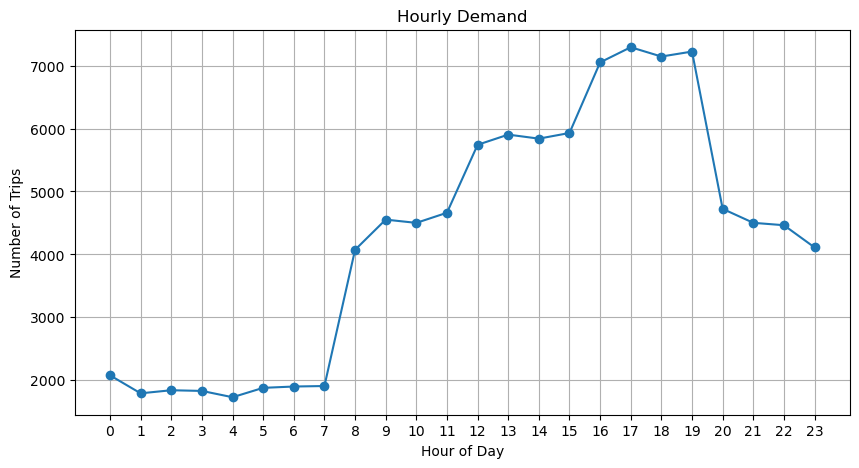

In [24]:
trips['time_start'] = pd.to_datetime(trips['time_start'], utc=True)
trips['hour_of_day'] = trips['time_start'].dt.hour
hourly_demand = trips.groupby('hour_of_day').size()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker='o')
plt.title('Hourly Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.grid(True)
plt.xticks(range(0, 24))
plt.show()


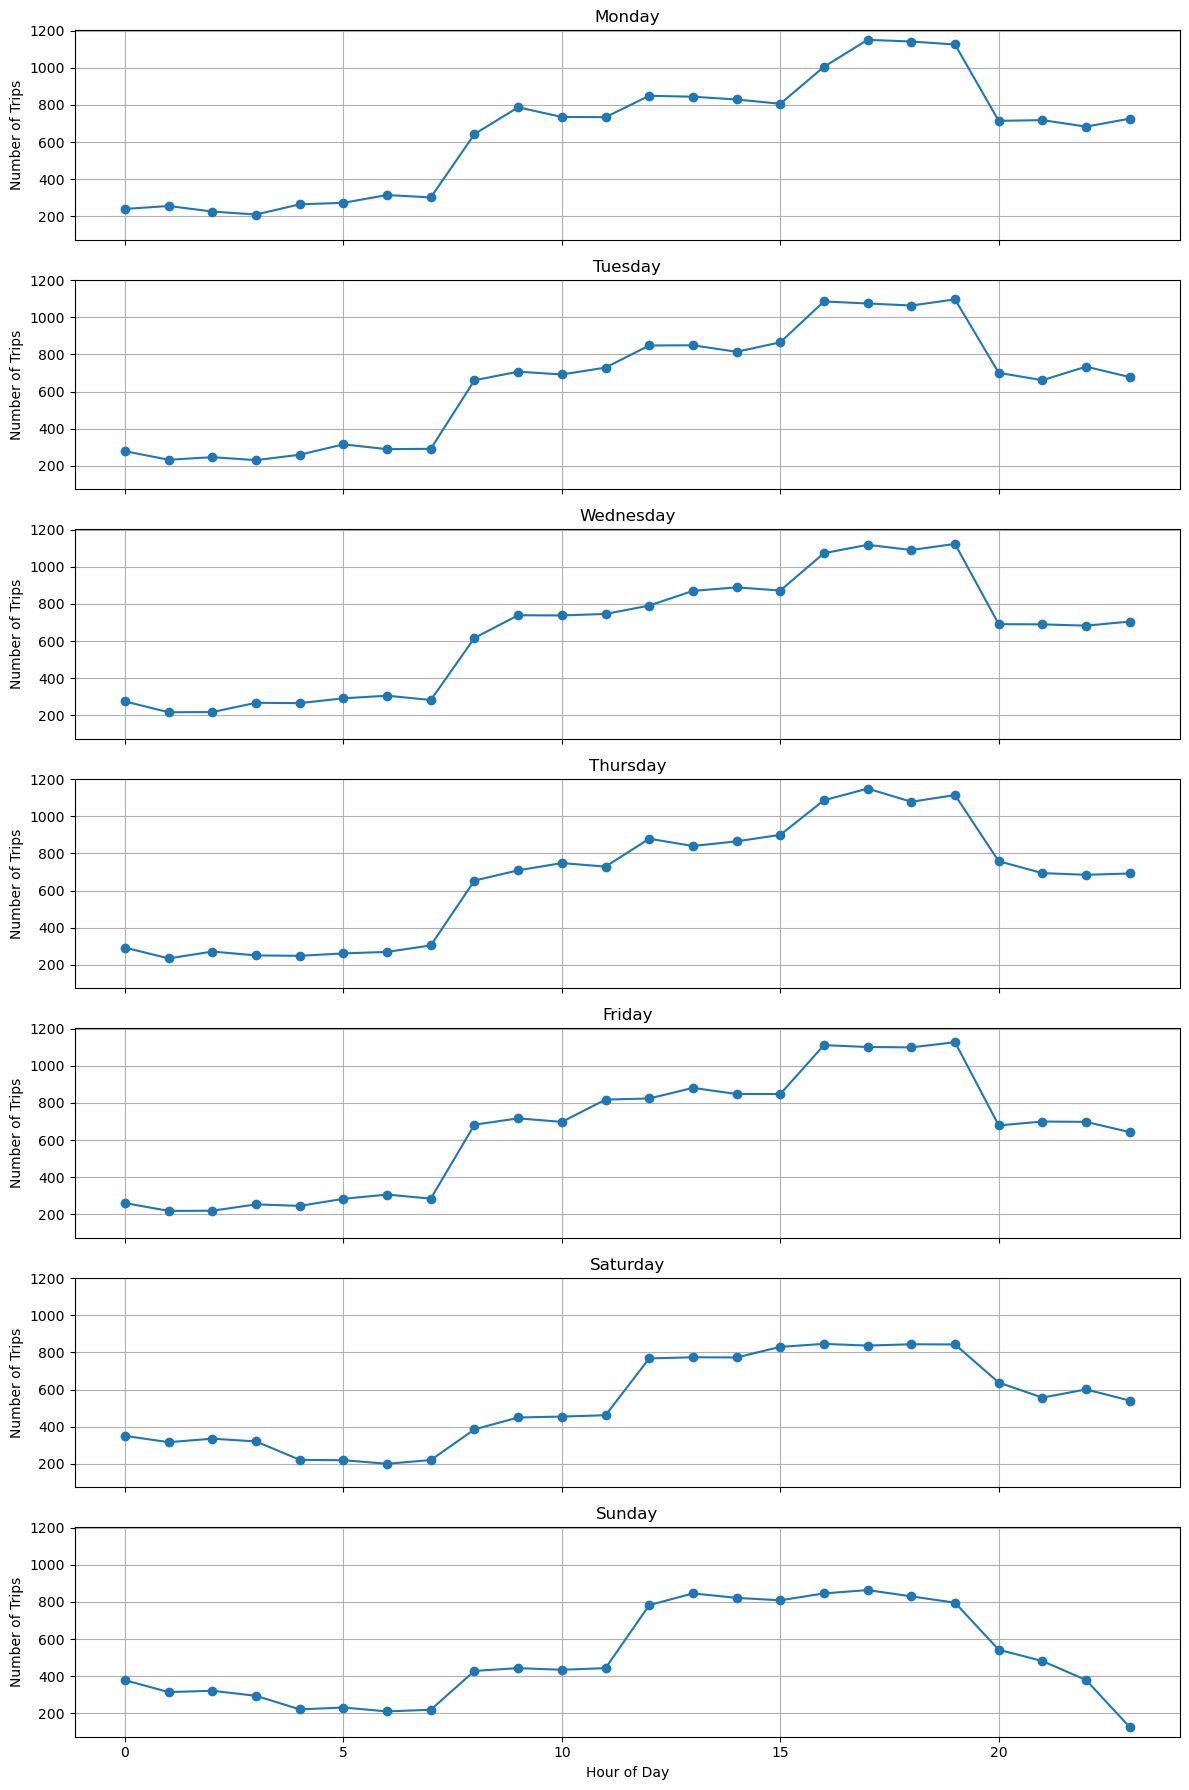

In [25]:
trips['time_start'] = pd.to_datetime(trips['time_start'])

# Extract the hour of the day and day of the week
trips['hour_of_day'] = trips['time_start'].dt.hour
trips['day_of_week'] = trips['time_start'].dt.dayofweek

# Group by day of week and hour of day and count the number of trips
daily_hourly_demand = trips.groupby(['day_of_week', 'hour_of_day']).size().unstack(fill_value=0)

# Plot the demand for each day of the week
fig, axes = plt.subplots(7, 1, figsize=(12, 18), sharex=True, sharey=True)

for day in range(7):
    axes[day].plot(daily_hourly_demand.columns, daily_hourly_demand.loc[day], marker='o')
    axes[day].set_title(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][day])
    axes[day].set_ylabel('Number of Trips')
    axes[day].grid(True)

plt.xlabel('Hour of Day')
plt.tight_layout()
plt.show()

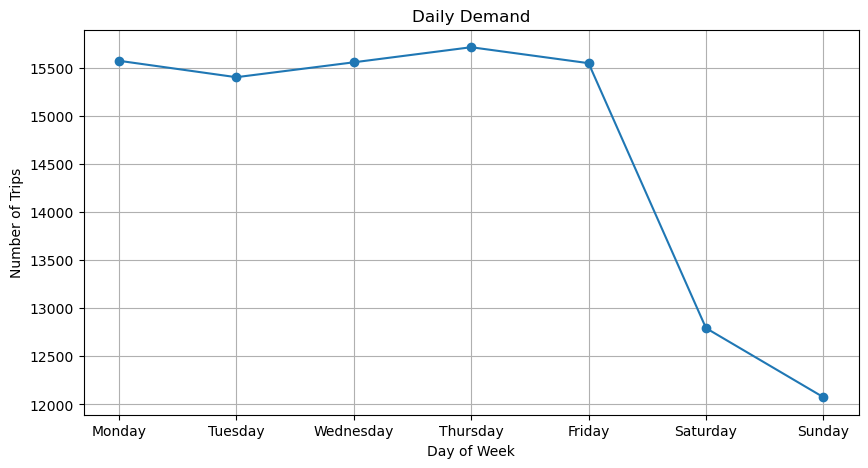

In [26]:
trips['day_of_week'] = trips['time_start'].dt.dayofweek
daily_demand = trips.groupby('day_of_week').size()

plt.figure(figsize=(10, 5))
plt.plot(daily_demand.index, daily_demand.values, marker='o')
plt.title('Daily Demand')
plt.xlabel('Day of Week')
plt.ylabel('Number of Trips')
plt.grid(True)
plt.xticks(range(0, 7), ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.show()

In [27]:
vehicle_demand = trips['vehicleType'].value_counts()

plt.figure(figsize=(10, 5))
vehicle_demand.plot(kind='bar', color='skyblue')
plt.title('Demand by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

KeyError: 'vehicleType'

In [ ]:
fleet_size = trips.groupby('vehicleType')['id'].nunique()

plt.figure(figsize=(10, 5))
fleet_size.plot(kind='bar', color='skyblue')
plt.title('Fleet Size by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Unique Vehicles')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [ ]:
provider_fleet = trips.groupby(['provider', 'vehicleType'])['id'].nunique().unstack(fill_value=0)

print(provider_fleet)
provider_fleet.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')
plt.title('Fleet Size by Provider and Vehicle Type')
plt.xlabel('Provider')
plt.ylabel('Number of Unique Vehicles')
plt.xticks(rotation=45)
plt.legend(title='Vehicle Type')
plt.grid(axis='y')
plt.show()

In [ ]:
provider_share = trips['provider'].value_counts()

# Calculate the percentage share of each provider
provider_share_percentage = (provider_share / provider_share.sum()) * 100

# Plot the share of each provider
plt.figure(figsize=(10, 5))
provider_share_percentage.plot(kind='bar', color='skyblue')
plt.title('Share of Each Provider')
plt.xlabel('Provider')
plt.ylabel('Percentage of Trips')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

## Trips Characteristics

In [ ]:
trips['duration_minutes'] = trips['duration'] / 60

general_avg_distance = trips['distance'].mean()
general_avg_duration = trips['duration_minutes'].mean()

# Calculate the average travel distance and time for each vehicle type
vehicle_type_avg = trips.groupby('vehicleType').agg({'distance': 'mean', 'duration_minutes': 'mean'}).reset_index()

# Plot the average travel distance for each vehicle type
plt.figure(figsize=(12, 6))

# Subplot for average travel distance
plt.subplot(1, 2, 1)
plt.bar(vehicle_type_avg['vehicleType'], vehicle_type_avg['distance'], color='skyblue')
plt.axhline(y=general_avg_distance, color='r', linestyle='--', label=f'General Avg: {general_avg_distance:.2f}')
plt.title('Average Travel Distance by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Distance')
plt.legend()
plt.grid(axis='y')

# Subplot for average travel duration
plt.subplot(1, 2, 2)
plt.bar(vehicle_type_avg['vehicleType'], vehicle_type_avg['duration_minutes'], color='lightgreen')
plt.axhline(y=general_avg_duration, color='r', linestyle='--', label=f'General Avg: {general_avg_duration:.2f} mins')
plt.title('Average Travel Time by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Duration (minutes)')
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()

# Display the general average travel distance and time
print(f"General Average Travel Distance: {general_avg_distance:.2f}")
print(f"General Average Travel Time: {general_avg_duration:.2f} minutes")

# Display the average travel distance and time for each vehicle type
vehicle_type_avg